# Applied Machine Learning - Credit Card Default Prediction

**Dataset:** UCI *Default of Credit Card Clients* (dataset not used in Projects 1 and 2).

This notebook will prepare the data, compare two classifiers by cross-validation, tune the stronger one, and evaluate it once on a held-out test set.


## How this notebook is organised

1. **Setup**: imports and package versions.
2. **Dataset loading and inspection**: shape, head, columns, dtypes, data quality.
3. **Preprocessing and train/test split**: rare-code folding, encoder/scaler pipeline, stratified split, traceability.
4. **Model comparison**: majority baseline, logistic regression vs random forest (5-fold CV ROC AUC).

> **TODO, in progress:** this notebook is being rebuilt section-by-section. Current progress: Setup, loading & inspection, preprocessing/split, model comparison added.


## Setup and reproducibility

- Fixed random seed (`RANDOM_STATE = 0`) for repeatable runs.
- `requirements.txt` is generated from this environment with `pip freeze`.


### Imports and version pin


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV, TunedThresholdClassifierCV,
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve,
    make_scorer,
)

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 30)

print(f"python {sys.version.split()[0]}")
print(f"numpy {np.__version__}")
print(f"pandas {pd.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"matplotlib {matplotlib.__version__}")

python 3.13.15
numpy 2.5.4
pandas 3.1.0
scikit-learn 1.9.1
matplotlib 3.11.2


## Dataset loading and inspection

- CSV loaded from disk; no network needed at run time.
- Shows shape, first rows, columns, and dtypes.


### Load CSV and preview


In [2]:
from pathlib import Path
CSV_PATH = Path("default_of_credit_card_clients.csv")
df = pd.read_csv(CSV_PATH)
print(f"shape {df.shape}")
df.head()

shape (30000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Columns, dtypes and memory


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   X1       30000 non-null  int64
 1   X2       30000 non-null  int64
 2   X3       30000 non-null  int64
 3   X4       30000 non-null  int64
 4   X5       30000 non-null  int64
 5   X6       30000 non-null  int64
 6   X7       30000 non-null  int64
 7   X8       30000 non-null  int64
 8   X9       30000 non-null  int64
 9   X10      30000 non-null  int64
 10  X11      30000 non-null  int64
 11  X12      30000 non-null  int64
 12  X13      30000 non-null  int64
 13  X14      30000 non-null  int64
 14  X15      30000 non-null  int64
 15  X16      30000 non-null  int64
 16  X17      30000 non-null  int64
 17  X18      30000 non-null  int64
 18  X19      30000 non-null  int64
 19  X20      30000 non-null  int64
 20  X21      30000 non-null  int64
 21  X22      30000 non-null  int64
 22  X23      30000 non-null  int64
 2

### Class balance, missing values and duplicates


missing values in the whole table: 0
duplicate rows: 35
default counts {0: 23364, 1: 6636}
default rate 0.2212


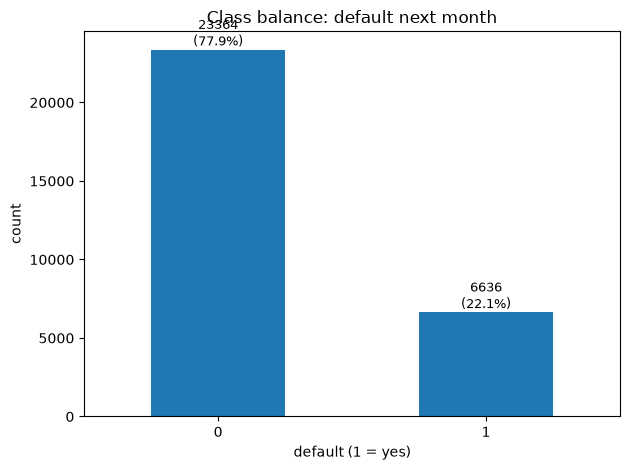

In [4]:
TARGET = "default"
missing = int(df.isnull().sum().sum())
dups = int(df.duplicated().sum())
counts = df[TARGET].value_counts().sort_index()
rate = float(df[TARGET].mean())
print(f"missing values in the whole table: {missing}")
print(f"duplicate rows: {dups}")
print(f"default counts {counts.to_dict()}")
print(f"default rate {rate:.4f}")
fig, ax = plt.subplots()
counts.plot(kind="bar", ax=ax, rot=0)
ax.set_title("Class balance: default next month")
ax.set_xlabel(f"{TARGET} (1 = yes)")
ax.set_ylabel("count")
for i, v in enumerate(counts):
    ax.text(i, v, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

**Data quality.**

- No missing values, output above: `missing values in the whole table: 0`.
- 35 rows are exact duplicates (label included); kept, since identical attribute patterns can belong to different clients, output above: `duplicate rows: 35`.
- Target imbalanced: about 22% default (`{0: 23364, 1: 6636}`, rate `0.2212`); metrics below are chosen for imbalance.


## Preprocessing and train/test split

**Explanatory draft.**

- **Fold rare codes.** `X3` (education) has values `0,5,6` that are undocumented / rare; `X4` (marital status) has `0`. We map them onto the documented buckets (`X3 {0,5,6} -> 4`, `X4 {0} -> 3`) so one-hot encoding does not create near-empty, uninformative columns.
- **One-hot encode categories.** `X2` (sex), `X3` (education), `X4` (marriage) are nominal, so `OneHotEncoder` turns them into binary columns; `handle_unknown='ignore'` keeps the pipeline safe if a new category appears later.
- **Standardize numerics.** The 20 numeric columns (limit X1, age X5, repayment status X6-X11, bill amounts X12-X17, payment amounts X18-X23) are on very different scales, so `StandardScaler` puts them on a common scale, needed for logistic regression and harmless for random forests.
- **No leakage.** `ColumnTransformer` is wrapped inside a `Pipeline` and only fitted inside each CV fold / on train, so test information never leaks into preprocessing.
- **Stratified split.** `train_test_split(test_size=0.2, stratify=y, RANDOM_STATE=0)` gives `24000` train / `6000` test, and both keep the default rate `0.2212` (so evaluation reflects the real class imbalance).

**Traceability (next cell).** We also count how many test rows are exact twins of train rows (`14`) and the share of clients with a negative bill amount (`0.0643`), since both affect how we read the later metrics.


### Fold rare codes, build preprocessor and stratified split


In [5]:
# --- categorical folding (rare codes) ---
df["X3"] = df["X3"].replace({0: 4, 5: 4, 6: 4})
df["X4"] = df["X4"].replace({0: 3})
print(f"X3 values after folding: {sorted(df['X3'].unique())}")
print(f"X4 values after folding: {sorted(df['X4'].unique())}")

# --- feature / target split ---
FEATURES = [c for c in df.columns if c != TARGET]
CAT_FEATURES = ["X2", "X3", "X4"]
NUM_FEATURES = [c for c in FEATURES if c not in CAT_FEATURES]
BILL_COLS = ["X12", "X13", "X14", "X15", "X16", "X17"]
X = df[FEATURES]
y = df[TARGET]

print(f"numeric features ({len(NUM_FEATURES)}): {NUM_FEATURES}")
print(f"categorical features ({len(CAT_FEATURES)}): {CAT_FEATURES}")

# --- preprocessor (no leakage: fit only inside CV/pipeline) ---
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES),
    ],
    verbose_feature_names_out=False,
)

# --- stratified train/test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"X_train {X_train.shape}  y_train rate {y_train.mean():.4f}")
print(f"X_test  {X_test.shape}  y_test  rate {y_test.mean():.4f}")


X3 values after folding: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
X4 values after folding: [np.int64(1), np.int64(2), np.int64(3)]
numeric features (20): ['X1', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']
categorical features (3): ['X2', 'X3', 'X4']
X_train (24000, 23)  y_train rate 0.2212
X_test  (6000, 23)  y_test  rate 0.2212


### Traceability, twins and negative-bill share


In [6]:
# --- traceability: duplicates & credit-balance ---
train_tuples = set(map(tuple, pd.concat([X_train, y_train], axis=1).to_numpy()))
test_tuples = list(map(tuple, pd.concat([X_test, y_test], axis=1).to_numpy()))
twin_in_train = sum(1 for t in test_tuples if t in train_tuples)
print(f"test rows with exact twin in train: {twin_in_train} ({twin_in_train / len(test_tuples):.2%} of test)")

neg_bill_share = (df[BILL_COLS] < 0).any(axis=1).mean()
print(f"share with negative bill amount: {neg_bill_share:.4f}")


test rows with exact twin in train: 14 (0.23% of test)
share with negative bill amount: 0.0643


**Traceability summary.**

- 14 test rows have an exact twin in the training set (same attribute pattern and label), `0.23%` of the 6000 test rows, output above: `test rows with exact twin in train: 14 (0.23% of test)`.
- 6.43% of clients have at least one negative bill-statement amount (credit balance, not debt), output above: `share with negative bill amount: 0.0643`.


## Model comparison (5-fold CV, ROC AUC)

- Majority-class baseline accuracy `0.7788` (always predict `0`).
- `LogisticRegression` vs `RandomForestClassifier` pipelines: `preprocessor` fitted inside each CV fold (no leakage).
- Metric `roc_auc` chosen for imbalanced target; 5-fold `cross_val_score` on **training set only**.


**Explanatory draft.**

- **What the baseline means.** Guessing "no default" for every client is right `0.7788` of the time, because most clients do not default. A useful model has to beat this trivial guess; if it cannot, it learns nothing worth having.
- **What the two models are.** Logistic regression writes one weighted score per feature and turns it into a probability: simple and readable. A random forest builds many decision trees on random slices of the data and lets them vote: much more flexible, harder to read.
- **Why ROC AUC and not accuracy.** Under imbalance, a model can look accurate while missing nearly all defaulters. ROC AUC instead asks: does the model place true defaulters higher in its ranking than non-defaulters? That works without choosing a cut-off.
- **Why 5-fold cross-validation.** A single train/validate split gets judged once; a lucky or unlucky split could decide the winner. Scoring 5 different splits and averaging averages away that luck.
- **Why training set only.** The 6000 held-out rows stay hidden until the final model exists. Tuning or comparing against them inflates the numbers you care about.


### Baselines and 5-fold CV (ROC AUC)


In [7]:
# --- baselines ---
from collections import Counter
majority_class = Counter(y_train).most_common(1)[0][0]
baseline_acc = (y_train == majority_class).mean()
print(f"majority class: {majority_class}  baseline train accuracy: {baseline_acc:.4f}")

# --- pipelines (preprocessing inside CV) ---
lr_pipe = Pipeline([("prep", clone(preprocessor)), ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
rf_pipe = Pipeline([("prep", clone(preprocessor)), ("clf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))])

# --- 5-fold CV ROC AUC on training data ---
for name, pipe in [("logistic regression", lr_pipe), ("random forest", rf_pipe)]:
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc", n_jobs=-1)
    print(f"{name:20s} CV ROC AUC {scores.mean():.4f} +/- {scores.std():.4f}  (folds: {scores.round(4).tolist()})")


majority class: 0  baseline train accuracy: 0.7788


logistic regression  CV ROC AUC 0.7266 +/- 0.0084  (folds: [0.7342, 0.7261, 0.7151, 0.72, 0.7374])


random forest        CV ROC AUC 0.7617 +/- 0.0078  (folds: [0.7749, 0.7515, 0.7585, 0.7649, 0.7589])


## Grid-search tuning (random forest)

- The random forest won the comparison above, so only it gets tuned; tuning runs on the **training set only** (`GridSearchCV`, 5-fold CV) and the test set stays untouched.
- Grid: `n_estimators` in `[100, 200]` x `max_depth` in `[10, 20]` (4 configurations), scored by ROC AUC.


**Explanatory draft.**

- **Why only the random forest.** Two models were compared just above and the random forest scored higher, so it is the one worth improving. It also has settings worth trying, while the logistic regression has almost none here.
- **What tuning means.** A random forest has settings chosen before training (hyperparameters): how many trees the forest contains and how deep each tree may grow. We do not guess them; we try a few sensible combinations and keep the one that scores best.
- **The grid.** `n_estimators` = number of trees in the forest (`100` or `200`); `max_depth` = how deep one tree is allowed to grow (`10` or `20` levels). That is `2 x 2 = 4` combinations in total.
- **How the winner is picked.** Each combination is judged like the comparison above: 5-fold cross-validation on the training set, ROC AUC as the score. In each fold, the model trains on 4 pieces of the training data and is checked on the 5th; the average ROC AUC across the 5 folds decides.
- **Why the test set stays untouched.** Trying settings until the test set looks good would be grading yourself on the exam questions. The test set is used once, later, on the single final model.


### GridSearchCV over forest size and depth


In [8]:
# --- grid-search tuning (train data only; test untouched) ---
rf_tune = Pipeline([
    ("prep", clone(preprocessor)),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [10, 20],
}
grid = GridSearchCV(rf_tune, param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
print(f"best params: {grid.best_params_}")
print(f"best CV ROC AUC: {grid.best_score_:.4f}")

results = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score"]]
results["mean_test_score"] = results["mean_test_score"].round(4)
results["std_test_score"] = results["std_test_score"].round(4)
print(results.sort_values("mean_test_score", ascending=False).to_string(index=False))


best params: {'clf__max_depth': 10, 'clf__n_estimators': 200}
best CV ROC AUC: 0.7795
                                          params  mean_test_score  std_test_score
{'clf__max_depth': 10, 'clf__n_estimators': 200}           0.7795          0.0071
{'clf__max_depth': 10, 'clf__n_estimators': 100}           0.7790          0.0069
{'clf__max_depth': 20, 'clf__n_estimators': 200}           0.7710          0.0062
{'clf__max_depth': 20, 'clf__n_estimators': 100}           0.7687          0.0062


## Evaluation on the test set, then a bank-cost view

- The tuned forest (`200` trees, depth `10`) is evaluated **once** on the `6000` held-out rows, at the standard `0.5` cut-off: accuracy, precision, recall, F1, ROC AUC, and the confusion matrix.
- Then the cut-off itself is tuned by money: each false alarm (FP) costs `1`, each missed defaulter (FN) costs `5`. `TunedThresholdClassifierCV` searches the cut-off on **training folds only**; the test set only receives the final comparison of gains.


**Explanatory draft.**

- **The confusion matrix named.** Four outcomes:
  - True negative: a safe client correctly cleared (no cost).
  - False positive: a safe client flagged for review (costs effort).
  - False negative: a defaulter waved through (costs the loss).
  - True positive: a defaulter caught in time.
- **What the probability means.** Each tree in the forest votes; the forest outputs the share that voted "default". A score of 0.7 means roughly 7 out of 10 trees think this client will default, 0.1 means almost none do, a confidence score, not a calibrated chance, but enough to rank clients and move the flag line without retraining.
- **Precision vs recall.** Recall asks "of everyone who actually defaulted, how many did we catch?" (`482 out of 1327 ≈ 0.3632` at `0.5`). Precision asks "of everyone we flagged, how many really defaulted?" (`482 out of 705 ≈ 0.6837` at `0.5`). They pull in opposite directions: catching more defaulters raises recall but lowers precision, as more safe clients are flagged too.
- **What a cut-off is.** It turns the score into a yes/no decision. The default `0.5` says "flag at half the trees yes." Lowering it to `0.174` flags more clients: more defaulters are caught (higher recall) at the price of more false alarms (lower precision).
- **Why "once".** Every look at the test set wears it out a little, like peeking at exam questions. All choices so far (folding, encoder, forest shape) were made without it; this is the one check that counts.
- **Why money, not ROC AUC.** The two error types have very different prices. A scorer that charges `1` per false alarm and `5` per missed defaulter lets the search compare cut-offs in the units the bank actually cares about.


### Tuned forest on the test set (cut-off 0.5)


In [9]:
# --- one-shot evaluation on the held-out test set ---
best_rf = grid.best_estimator_
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

print(f"accuracy  {accuracy_score(y_test, y_pred):.4f}")
print(f"precision {precision_score(y_test, y_pred):.4f}")
print(f"recall    {recall_score(y_test, y_pred):.4f}")
print(f"f1        {f1_score(y_test, y_pred):.4f}")
print(f"roc auc   {roc_auc_score(y_test, y_prob):.4f}")
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"confusion TN {tn} / FP {fp} / FN {fn} / TP {tp}")


accuracy  0.8220
precision 0.6837
recall    0.3632
f1        0.4744
roc auc   0.7799
confusion TN 4450 / FP 223 / FN 845 / TP 482


### Tune the cut-off on training folds (FP cost 1, FN cost 5)


In [10]:
# --- bank gain: larger is better; FP costs 1 unit, FN costs 5 ---
def bank_gain(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return -(fp + 5 * fn)

gain_scorer = make_scorer(bank_gain)

tuned_rf = TunedThresholdClassifierCV(
    estimator=grid.best_estimator_,
    scoring=gain_scorer,
    cv=5,
)
tuned_rf.fit(X_train, y_train)
print(f"tuned cut-off: {tuned_rf.best_threshold_:.3f}")

gain_default = bank_gain(y_test, best_rf.predict(X_test))
gain_tuned = bank_gain(y_test, tuned_rf.predict(X_test))
print(f"test gain at 0.5 cut-off:  {gain_default}")
print(f"test gain at tuned cut-off: {gain_tuned}")

tp_tuned = tuned_rf.predict(X_test)
print(f"tuned-cutoff recall    {recall_score(y_test, tp_tuned):.4f}")
print(f"tuned-cutoff precision {precision_score(y_test, tp_tuned):.4f}")
print(f"tuned-cutoff f1        {f1_score(y_test, tp_tuned):.4f}")


tuned cut-off: 0.174
test gain at 0.5 cut-off:  -4448
test gain at tuned cut-off: -3347
tuned-cutoff recall    0.7159
tuned-cutoff precision 0.3939
tuned-cutoff f1        0.5082
